# The Argo Data Analysis
-------
# ⁕1. Introduction and Background
### 1.1 Scientific Objective

This analysis investigates whether the saltiest high-latitude surface waters are also the densest, or whether temperature exerts the stronger control on buoyancy across the North Atlantic, Southern Ocean, and Arctic. At the outset, the North Atlantic appears the most likely candidate for the densest surface regime because it contains the highest salinity values in the dataset, but this study tests the competing possibility that extreme polar cooling in the Southern Ocean can outweigh that salinity advantage and reverse the density ranking. By calculating TEOS-10 density from Argo surface temperature and salinity observations, the analysis traces how contrasting thermohaline signatures produce three different physical states: a warm saline Atlantic, a frigid dense Southern Ocean, and a fresh stratified Arctic. The central aim is therefore not only to describe basin differences, but to determine which variable actually governs surface density in this dataset and why the apparently intuitive expectation based on salinity alone fails.

### 1.2 The Argo Array
Argo is a global array of nearly 4,000 profiling floats collect *in situ* data that measure temperature and salinity through the upper 2,000 m of the ocean on roughly 10-day cycles, providing the observational backbone for broad-scale physical oceanography (Johnson, G. et al., 2021).\
The dataset used in this analysis is derived from the [Argo](https://en.wikipedia.org/wiki/Argo_(oceanography)) array, an international ocean observation program that collects in situ data using a global network of free-drifting profiling floats. Providing over 100,000 profiles and reference velocity measurements annually, the Argo program has revolutionized observational oceanography. The data are critical for initializing coupled climate forecast models, testing dynamical ocean models, and crucially for this analysis—monitoring continuous thermohaline shifts and large-scale ocean dynamics in historically under-sampled, high-latitude regions.
<center><img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/e/e2/BrnBld_ArgoFloat.svg/960px-BrnBld_ArgoFloat.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail" width="150" ><img src="https://media1.tenor.com/m/3_Ljp8tORC4AAAAd/usagi-chiikawa.gif" width="300"></center>
<center>This diagram (left) shows the general structure of a free drifting profiling float. (the right one is usagi floating up and down in hot springs)</center>


<center><img src="https://csiro.silverchair-cdn.com/csiro/content_public/cms/news/7535/oceanwarming-argo-2025-map.jpg?Expires=2147483647&Signature=kJUhCEm369J8qi6Gq5I9bgyZuqgZzKSxfDQshZR~5oev0-FolEMc0IrYywitzVuLFkSt7axIsbFREqwlZLpbcIqYbJnyjIXC32iqm245am1rGqhpmrjdIvvb48G8ukf0yAzfYmLB5JJIu15tccw3KEiRkIXF5jsJl0i7lHyAKck4guwHF5NZA07bG2Ld9KAI1yUcF6xJ7hzPwox4S7db4jqgYhvQsbhCKVXtasCX8iXBlTdepjHJP5kBq~VvwGlwryTn8-UpyJXMSwJGFL4nkhbKebm7nCy50eXV2zVCW0fQGRIj6GqG28dMe40vHZ4KH5Se6fIlSgN~EaiR~1zxJg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA" width="400" >
<img src="https://media.tenor.com/lSa7Hxu-qDUAAAAM/watchingyou-peeking.gif" width="270"></center>

Captured in November 2025, this map plots nearly 4,000 active Argo floats. Think of them as a global fleet of **underwater spies** : appearing to just travel in the sea and drift aimlessly with the currents, while secretly gathering critical intelligence. They form an autonomous espionage network, continuously diving to 2,000 meters and resurfacing. Instead of military secrets, these sentinels collect high-resolution vertical profiles of temperature and salinity. This continuous, undercover data stream provides the real-time snapshots necessary to monitor the ocean’s shifting physics, from shrinking polar ice caps to the weakening of the global overturning circulation. Over the past two decades, Argo has produced more than two million temperature–salinity profiles and substantially improved ocean monitoring, forecasting, and climate-relevant ocean analysis (Wong, A. et al., 2020).

### 1.3 TEOS-10 Equation of State
Seawater density in this study was computed using [Thermodynamic Equation of Seawater 2010 (TEOS-10)](https://en.wikipedia.org/wiki/TEOS-10), the current international standard, which evaluates thermodynamic properties from Absolute Salinity, temperature, and pressure and replaced EOS-80 as the recommended seawater framework (Feistel, R., 2018). Rather than using legacy Practical Salinity metrics, it calculates thermodynamic properties based on Absolute Salinity and Conservative Temperature, where absolute Salinity is the appropriate salinity variable for density-based dynamical calculations because it accounts for composition-related variability that Practical Salinity does not represent (McDougall, T. et al., 2010). By accounting for spatial variations in the actual chemical composition of seawater, this modern approach provides the mathematically rigorous and thermodynamically consistent density measurements required for high-latitude climate analysis (IOC, SCOR and IAPSO, 2010).

------
# ⁕2. Methodology and Computational Approach


First we need to load the packages and initialize the routine for computing TEOS-10 density before we enter the analysis:

In [1]:
#Load packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress verbose warnings to maintain a clean presentation
import warnings
warnings.filterwarnings('ignore')


#   routine for computing TEOS-10 density
#   [forced p=0 because this is surface argo data we are dealing with]
def sigmai_dep(CT, SA, p=0):
    """
    Compute the in-situ (or potential) density from CONSERVATIVE Temperature, 
    ABSOLUTE Salinity and pressure fields using the TEOS-10 EOS

    p can be a field (computed with subroutine p_from_z say) to get in-situ 
    density or can be a number p = p_ref, then it is a potential density 
    referenced to p_ref

    Adapted from the MATLAB GSW toolbox (http://www.TEOS-10.org)

    Inputs:
    CT             = Conservative Temperature      t        deg celsius
    SA             = Absolute Salinity             s        g / kg
    p              = (reference) pressure          p        dbar

    Returns:
    sigmai_dep_out = (potential density            rho      kg / m^3

    """
    # ensures that SA is non-negative.
    SA = abs(SA)

    # deltaS = 24
    sfac = 0.0248826675584615                 # sfac   = 1/(40*(35.16504/35)).
    offset = 5.971840214030754e-1             # offset = deltaS*sfac.

    x2 = sfac * SA
    xs = np.sqrt(x2 + offset)
    ys = CT * 0.025
    z  = p * 1e-4

    v000 =  1.0769995862e-3
    v001 = -6.0799143809e-5
    v002 =  9.9856169219e-6
    v003 = -1.1309361437e-6
    v004 =  1.0531153080e-7
    v005 = -1.2647261286e-8
    v006 =  1.9613503930e-9
    v010 = -1.5649734675e-5
    v011 =  1.8505765429e-5
    v012 = -1.1736386731e-6
    v013 = -3.6527006553e-7
    v014 =  3.1454099902e-7
    v020 =  2.7762106484e-5
    v021 = -1.1716606853e-5
    v022 =  2.1305028740e-6
    v023 =  2.8695905159e-7
    v030 = -1.6521159259e-5
    v031 =  7.9279656173e-6
    v032 = -4.6132540037e-7
    v040 =  6.9111322702e-6
    v041 = -3.4102187482e-6
    v042 = -6.3352916514e-8
    v050 = -8.0539615540e-7
    v051 =  5.0736766814e-7
    v060 =  2.0543094268e-7
    v100 = -3.1038981976e-4
    v101 =  2.4262468747e-5
    v102 = -5.8484432984e-7
    v103 =  3.6310188515e-7
    v104 = -1.1147125423e-7
    v110 =  3.5009599764e-5
    v111 = -9.5677088156e-6
    v112 = -5.5699154557e-6
    v113 = -2.7295696237e-7
    v120 = -3.7435842344e-5
    v121 = -2.3678308361e-7
    v122 =  3.9137387080e-7
    v130 =  2.4141479483e-5
    v131 = -3.4558773655e-6
    v132 =  7.7618888092e-9
    v140 = -8.7595873154e-6
    v141 =  1.2956717783e-6
    v150 = -3.3052758900e-7
    v200 =  6.6928067038e-4
    v201 = -3.4792460974e-5
    v202 = -4.8122251597e-6
    v203 =  1.6746303780e-8
    v210 = -4.3592678561e-5
    v211 =  1.1100834765e-5
    v212 =  5.4620748834e-6
    v220 =  3.5907822760e-5
    v221 =  2.9283346295e-6
    v222 = -6.5731104067e-7
    v230 = -1.4353633048e-5
    v231 =  3.1655306078e-7
    v240 =  4.3703680598e-6
    v300 = -8.5047933937e-4
    v301 =  3.7470777305e-5
    v302 =  4.9263106998e-6
    v310 =  3.4532461828e-5
    v311 = -9.8447117844e-6
    v312 = -1.3544185627e-6
    v320 = -1.8698584187e-5
    v321 = -4.8826139200e-7
    v330 =  2.2863324556e-6
    v400 =  5.8086069943e-4
    v401 = -1.7322218612e-5
    v402 = -1.7811974727e-6
    v410 = -1.1959409788e-5
    v411 =  2.5909225260e-6
    v420 =  3.8595339244e-6
    v500 = -2.1092370507e-4
    v501 =  3.0927427253e-6
    v510 =  1.3864594581e-6
    v600 =  3.1932457305e-5

    v = v000 + ( 
        xs * (v100 + xs * (v200 + xs * (v300 + xs * (v400 + xs * (v500 
      + v600 * xs))))) + ys * (v010 + xs * (v110 + xs * (v210 + xs * (v310 
      + xs * (v410 + v510 * xs)))) + ys * (v020 + xs * (v120 + xs * (v220 
      + xs * (v320 + v420 * xs))) + ys * (v030 + xs * (v130 + xs * (v230 
      + v330 * xs)) + ys * (v040 + xs * (v140 + v240*xs) + ys * (v050 
      + v150 * xs + v060 * ys))))) + z * (v001 + xs * (v101 + xs * (v201 
      + xs * (v301 + xs * (v401 + v501 * xs)))) + ys * (v011 + xs * (v111
      + xs * (v211 + xs * (v311 + v411 * xs))) + ys * (v021 + xs * (v121 
      + xs * (v221 + v321 * xs)) + ys * (v031 + xs * (v131 + v231 * xs) 
      + ys * (v041 + v141 * xs + v051 * ys)))) + z * (v002 + xs * (v102 
      + xs * (v202 + xs * (v302 + v402 * xs))) + ys * (v012 + xs * (v112 
      + xs * (v212 + v312 * xs)) + ys * (v022 + xs * (v122 + v222 * xs) 
      + ys * (v032 + v132 * xs + v042 * ys))) + z * (v003 + xs * (v103 
      + v203 * xs) + ys * (v013 + v113 * xs + v023 * ys) + z * (v004 
      + v104 * xs + v014 * ys + z * (v005 + v006 * z)))))
              )

    sigmai_dep_out = (1 / v) - 1000

    return sigmai_dep_out

### 2.1 Data Source and Technical Structure
This analysis leverages Python to process, analyze, and visualize the Argo float dataset. The raw surface data ([argo_data.csv](https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/argo_data.csv)) is loaded and structured using `pandas` DataFrames. To compute thermodynamic density via the TEOS-10 subroutine, temperature and salinity vectors are cast as `numpy` arrays to maximize numerical efficiency. Subsequent summary statistics and spatial thermohaline distributions specifically targeting the three high-latitude regions (North Atlantic, Southern Ocean, and Arctic), which are quantified using aggregation methods and visualized via `matplotlib` and `seaborn`.

Here we load the dataset and compute dataset information:

In [2]:
# Ingest the dataset
path = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/argo_data.csv"
df = pd.read_csv(path)

# Output dataset dimensions, variable names, and data types
print("Dataset Information:")
df.info()

# Display the unique ocean basins available in the dataset
print("\nBasins represented:", df['basin'].unique())

# Check for missing data
print("\nMissing Values:")
print(df.isnull().sum())

# Display the dataframe to verfy the structure
df

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   temperature_degC  600 non-null    float64
 1   salinity_g/kg     600 non-null    float64
 2   basin             600 non-null    str    
dtypes: float64(2), str(1)
memory usage: 20.1 KB

Basins represented: <ArrowStringArray>
['N_Atlantic', 'Arctic', 'Southern_Ocean']
Length: 3, dtype: str

Missing Values:
temperature_degC    0
salinity_g/kg       0
basin               0
dtype: int64


,temperature_degC,salinity_g/kg,basin
0,24.476994,36.389008,N_Atlantic
1,22.151000,36.496300,N_Atlantic
2,25.657673,36.368990,N_Atlantic
3,25.245024,37.482990,N_Atlantic
4,26.277857,35.767467,N_Atlantic
...,...,...,...
595,0.939000,34.028200,Southern_Ocean
596,-1.812342,34.042267,Southern_Ocean
597,0.320086,33.696743,Southern_Ocean
598,2.393308,33.972248,Southern_Ocean


### 2.2 Analytical Pipeline
To translate the high-latitude Argo measurements into actionable climate insights, this analysis executes a streamlined three-step computational workflow:

1. **Data Ingestion:** The dataset (argo_data.csv) is imported directly into `pandas` DataFrames, preserving its regional partitioning across the North Atlantic, Southern Ocean, and Arctic.
2. **Thermodynamic Density Calculation:** Temperature and salinity vectors are passed through the TEOS-10 subroutine to derive accurate absolute water densities, quantifying local surface stratification.
3. **Thermohaline Profiling:** Temperature-Salinity (T-S) diagrams and statistical distributions are generated to visually isolate distinct polar water masses and determine regional density drivers.

------
# 3. Results: Thermohaline Analysis by Basin

### 3.1 Zeroth-Order Data Inspection
Initial inspection of the dataset reveals 600 discrete surface ocean observations. The tabular structure comprises three key variables:

*   **`temperature`**: *In situ* ocean surface temperature, measured in degrees Celsius (°C).
*   **`salinity`**: Ocean surface salinity, measured in Absolute Salinity (g/kg).
*   **`basin`**: A categorical geographic identifier designating the source profile: **Arctic**, **North Atlantic**, or **Southern Ocean**.

The dataset exhibits complete data integrity with zero missing values. Numerical fields (`temperature`, `salinity`) are appropriately formatted as continuous floating-point arrays, enabling immediate thermodynamic computation and spatial aggregation.

### 3.2 Thermohaline Summary Statistics by Basin
To evaluate regional thermodynamic variations, the dataset is grouped by ocean basin. The following analysis quantifies central tendencies and dispersion metrics for surface temperature and salinity across the three polar regimes. Specifically the mean, standard deviation, and range.

Here we calculate basic statistics of the three basins:

In [3]:
# Group data by basin and calculate summary statistics for primary variables
basin_stats = df.groupby('basin')[['temperature_degC', 'salinity_g/kg']].describe()
# Format the output for clean presentation
display(basin_stats.round(2))

temperature_degC                                                \
                          count   mean   std   min    25%    50%    75%   max   
basin                                                                           
Arctic                    200.0   8.77  3.40  0.56   5.90   8.77  11.41  17.6   
N_Atlantic                200.0  22.32  4.99  7.35  18.86  23.56  26.20  28.9   
Southern_Ocean            200.0   1.63  2.64 -1.86  -0.61   1.28   3.55   7.9   

               salinity_g/kg                                                  
                       count   mean   std    min    25%    50%    75%    max  
basin                                                                         
Arctic                 200.0  34.87  0.51  31.26  34.69  34.91  35.15  35.65  
N_Atlantic             200.0  36.23  0.87  32.11  35.83  36.38  36.75  38.80  
Southern_Ocean         200.0  33.94  0.16  33.10  33.85  33.93  34.03  34.45

#### Scientific Rationalization

The summary statistics reveal distinct thermodynamic signatures across the three basins:

*   **Salinity Extremes:** The North Atlantic exhibits the highest mean surface salinity (36.23 g/kg, peaking at 38.80 g/kg). This is driven by intense atmospheric forcing where regional evaporation dramatically exceeds precipitation. In contrast, the Southern Ocean maintains a much fresher, tightly bounded profile (mean 33.94 g/kg with a standard deviation of just 0.16 g/kg), heavily buffered by high precipitation and polar discharge. Notably, the Arctic captures the lowest overall surface salinity (31.26 g/kg), directly reflecting the buoyant freshwater cap created by river runoff and melting sea ice.

*   **Temperature Variance:** The North Atlantic records both the highest mean surface temperature (22.32 °C) and the widest thermal dispersion (std 4.99, spanning 7.35 °C to 28.90 °C). This broad range captures float sampling from warm subtropical waters up to cooler subpolar masses. By contrast, the Southern Ocean is dominated by extreme cold, averaging just 1.63 °C and reaching down to -1.86 °C near the freezing point of seawater.

**Applying TEOS-10 for Density Calculation**\
To evaluate how these thermal and haline signatures govern ocean stratification, surface water density must be derived using the Thermodynamic Equation of Seawater 2010 (TEOS-10). The following computational step applies the TEOS-10 subroutine to convert the observed temperature and salinity arrays into a primary physical variable for surface density ($\rho$).

In [4]:
# Extract full columns as numpy arrays for efficient computation
T_array = df['temperature_degC'].values
S_array = df['salinity_g/kg'].values

# Calculate density for the entire dataset using the provided subroutine
df['density_$\rho$'] = sigmai_dep(T_array, S_array)

# Group by basin to calculate summary statistics for temperature, salinity, and density
basin_stats = df.groupby('basin')[['temperature_degC', 'salinity_g/kg', 'density_$\rho$']].describe()

# Format the output for a clean, professional presentation
display(basin_stats.round(2))

temperature_degC                                                \
                          count   mean   std   min    25%    50%    75%   max   
basin                                                                           
Arctic                    200.0   8.77  3.40  0.56   5.90   8.77  11.41  17.6   
N_Atlantic                200.0  22.32  4.99  7.35  18.86  23.56  26.20  28.9   
Southern_Ocean            200.0   1.63  2.64 -1.86  -0.61   1.28   3.55   7.9   

               salinity_g/kg         ...               density_$\rho$         \
                       count   mean  ...    75%    max          count   mean   
basin                                ...                                       
Arctic                 200.0  34.87  ...  35.15  35.65          200.0  26.87   
N_Atlantic             200.0  36.23  ...  36.75  38.80          200.0  24.82   
Southern_Ocean         200.0  33.94  ...  34.03  34.45          200.0  26.98   

                                                         
                 std    min    25%    50%    75%    max  
basin                                                    
Arctic          0.54  24.59  26.58  26.97  27.28  27.74  
N_Atlantic      1.36  21.04  23.79  24.95  25.86  28.40  
Southern_Ocean  0.23  26.44  26.82  27.00  27.13  27.61  

[3 rows x 24 columns]

#### Density Statistics and Interpretation

* **Mean ranking inverts salinity ranking**: the Southern Ocean is densest (26.98 g/kg) and the North Atlantic lightest (24.82 g/kg) despite its highest salinity, because its warmth counteracts the salt.
* **Dispersion, not the mean, distinguishes basins**: the North Atlantic has the widest spread (std 1.36) and its maximum exceeds both polar basins, so a low mean does not imply uniformly light water.
* **Two polar basins share similar means but different spreads**: the Southern Ocean's compact distribution (std 0.23, narrow IQR) reflects its tight salinity and weak low-temperature thermal sensitivity. The Arctic's wider spread comes from broader T and S ranges than the Southern Ocean.

Basin means conceal distributional differences. These surface statistics bound buoyancy contrast but cannot establish stratification or convection. The following part shows more clear visualisation. 

### 3.3 Thermohaline Distributions and Thermal Variance
To visualize the thermodynamic structure of our high-latitude surface waters, here we generate two diagnostic plots:

1. **Temperature-Salinity (T-S) Diagram (left):** Identifies distinct regional water masses and maps their specific salinity gradients against the newly computed TEOS-10 density contours.
2. **Thermal Variance Boxplot (right):** Quantifies the thermal spread, central medians, and extreme latitudinal outliers within each basin, highlighting the stark contrast between the North Atlantic's broad thermal range and the tightly constrained freezing profiles of the polar oceans.

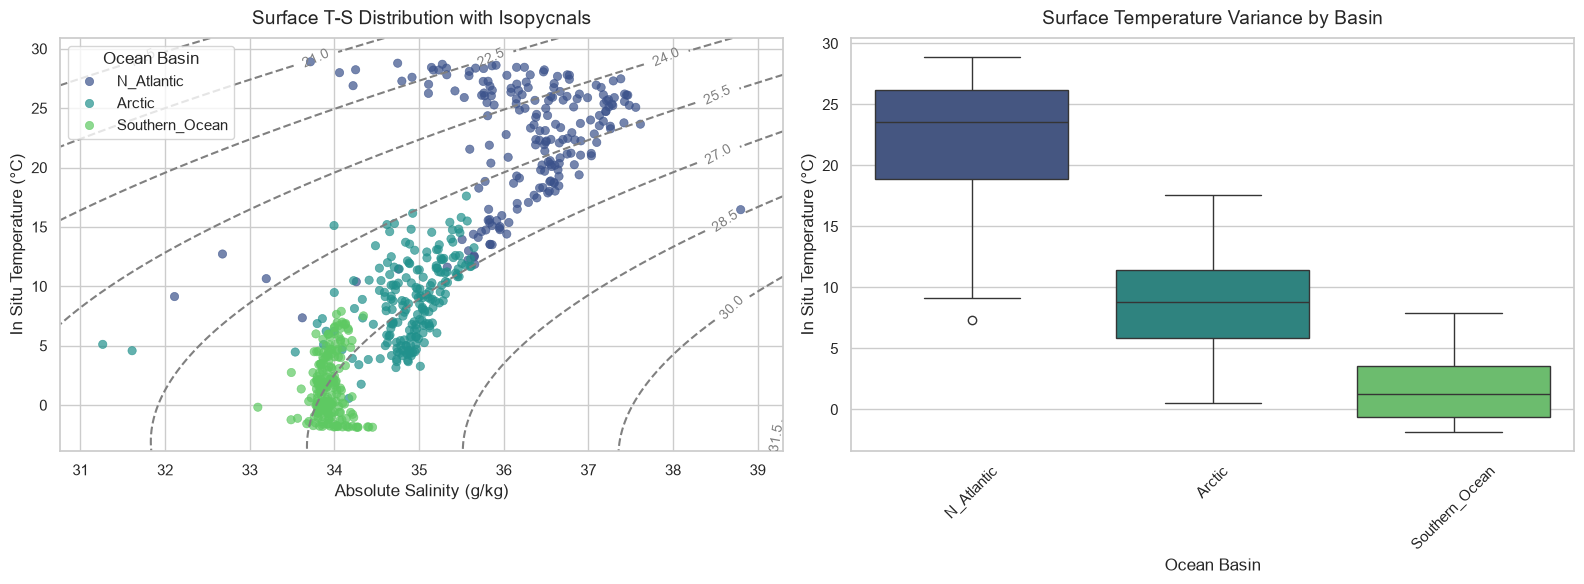

In [5]:
# Set the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: T-S Diagram with Density Contours ---

# 1. Create a grid of Temperature and Salinity values for the background
s_min, s_max = df['salinity_g/kg'].min() - 0.5, df['salinity_g/kg'].max() + 0.5
t_min, t_max = df['temperature_degC'].min() - 2, df['temperature_degC'].max() + 2
s_grid = np.linspace(s_min, s_max, 100)
t_grid = np.linspace(t_min, t_max, 100)
S_mesh, T_mesh = np.meshgrid(s_grid, t_grid)

# 2. Calculate density for the entire background grid using your subroutine
# Note: Ensure sigmai_dep can handle 2D meshgrid arrays, or flatten/reshape if needed
Density_mesh = sigmai_dep(T_mesh, S_mesh)

# 3. Plot the background density contours
contour = axes[0].contour(S_mesh, T_mesh, Density_mesh, levels=10, colors='gray', linestyles='dashed')
axes[0].clabel(contour, inline=True, fontsize=10, fmt='%1.1f')

# 4. Plot the actual Argo data points on top
sns.scatterplot(
    ax=axes[0],
    data=df, 
    x='salinity_g/kg', 
    y='temperature_degC', 
    hue='basin', 
    palette='viridis', 
    alpha=0.7,
    edgecolor=None
)

axes[0].set_title('Surface T-S Distribution with Isopycnals', fontsize=14, pad=10)
axes[0].set_xlabel('Absolute Salinity (g/kg)', fontsize=12)
axes[0].set_ylabel('In Situ Temperature (°C)', fontsize=12)
axes[0].legend(title='Ocean Basin')

# --- Plot 2: Boxplot of Temperature by Basin ---
sns.boxplot(
    ax=axes[1],
    data=df,
    x='basin',
    y='temperature_degC',
    palette='viridis'
)
axes[1].set_title('Surface Temperature Variance by Basin', fontsize=14, pad=10)
axes[1].set_xlabel('Ocean Basin', fontsize=12)
axes[1].set_ylabel('In Situ Temperature (°C)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45) 

plt.tight_layout()
plt.show()

#### Visual Interpretation

**1. Water Mass Signatures (T-S Diagram)**
The T-S diagram acts as a diagnostic fingerprint, mapping the three distinct regional water masses against curved isopycnals (lines of constant density).

* **The Warm, Saline Atlantic:** The North Atlantic data points form a broad cluster dominating the high-temperature (7.35 to 28.90 °C)( from previous statistics) and high-salinity (32.11 to 38.80 g/kg) upper right quadrant. This massive spread across multiple density contours reflects the warm, salty waters originated from subtropical regions, where evaporation significantly outpaces precipitation, is transported northward by the Gulf Stream.


* **The Polar Extremes:** Down in the bottom left, the Southern Ocean cluster is tightly packed in extreme cold (-1.86 to 7.90 °C) within a narrow, lower-salinity band (33.10 to 34.45 g/kg)(I take these data from previous statistics for reference because it is more accurate). This dense clustering indicates a highly uniform polar water mass buffered by glacial melt and high polar precipitation, while the Arctic occupies the lower-salinity(slightly higher than Southern Ocean) domains forms the freshest extreme, reflecting a buoyant surface cap driven by river runoff and melting sea ice.


* **The Arctic Mixing Line:** The Arctic points form a distinct diagonal streak bridging the gap between the frigid Southern Ocean cluster and the warmer Atlantic waters. This linear gradient visually captures the transitional mixing of cold, fresh polar runoff with saltier sub-polar currents, where the Argo sentinels drift across active frontal boundaries. The background isopycnal contours (lines of constant density) demonstrate exactly how these intersecting temperature and salinity signatures dictate whether surface water floats or sinks.


**2. Thermal Variance and Stratification (Boxplot)**
The boxplot provides a clear statistical breakdown of latitudinal temperature distributions, highlighting extreme regional contrasts.

* **Central Tendencies:** The median surface temperature is drastically higher in the North Atlantic (approx. 23 °C) compared to the Arctic (approx. 9 °C) and the Southern Ocean (hovering near 1 °C). Because the Arctic and Southern Oceans are strictly frigid polar regimes, the North Atlantic's elevated median reflects the massive thermal transport of the overturning circulation pulling heat into the subpolar latitudes.


* **Thermal Range and Outliers:** The North Atlantic exhibits massive thermal variance, featuring a wide interquartile range and whiskers stretching from 9 up to 29 °C, alongside a single cold outlier near 7 °C. The wide interquartile range in the North Atlantic indicates a broad latitudinal spread, capturing heat transport from warmer mid-latitudes all the way up to cold, sub-polar sinking zones. By contrast, the Southern Ocean is highly constrained, with its entire interquartile range locked tightly around the freezing point. The presence of lower-bound outliers in the Southern Ocean highlights isolated float observations directly along the Antarctic sea-ice margins, where the water approaches absolute freezing (-1.8 °C).

### 3.4 Global Ocean Circulation Context and Forcing

To bridge the gap between descriptive summary statistics and the underlying dynamic oceanographic mechanisms, this part examines the broader framework of the [Thermohaline Circulation (the "Great Ocean Conveyor Belt")](https://en.wikipedia.org/wiki/Thermohaline_circulation). It is the transport of deep water between the Atlantic, the Indian and the Pacific Ocean, described in terms of the ‘Great Conveyor Belt’ concept (Broeker, W., 2008).

Functionally, this system operates as **Earth's planetary cardiovascular system**. Instead of circulating oxygenated blood through blood vessels to facilitate body functions, it pumps massive quantities of thermal energy and dissolved salts across global ocean basins. The wind-driven surface currents act as the "arteries," carrying warm, buoyant water poleward to regulate Earth's climate. Conversely, the dense, sinking water masses formed at the polar extremes act as deep-ocean "veins," sluggishly returning frigid bottom water to complete the planetary circuit. The global overturning circulation redistributes heat and carbon across ocean basins and is controlled primarily by convection, mixing, and wind-driven processes (Roquet, F. et al., 2025). 

<center><img src="https://cdn.corenexis.com/f/fTWImGO6Czf.jpeg" width="400"><img src="https://media.tenor.com/bAZDKHwAsUAAAAAM/%E5%BF%AB%E6%BB%BE-platelets.gif" width="200">
</center>
<center>I stole the conveyor belt picture from OCES2004 lecture notes but I forgot which chapter it is</center>

#### Key Regional Mechanisms Driven by Surface Physics

*   **The Atmospheric "Freshwater Bridge":** Oceanographically, prevailing trade winds drive intense evaporation in the subtropical Atlantic, continuously exporting water vapor across Central America into the Pacific Basin. This atmospheric transport leaves behind an elevated baseline salinity in Atlantic surface waters before they even begin their journey northward.
*   **The Atlantic "Heat/Salt Pump":** Major western boundary currents like the Gulf Stream and North Atlantic Current, act as high-capacity "arteries". They transport immense volumes of warm, highly saline subtropical water into the subpolar target zones evaluated in the Argo dataset.
*   **Thermohaline Preconditioning for Sinking:** This planetary conveyor belt explains why the North Atlantic and Southern Ocean host the densest surface waters. As warm, salty surface water flows poleward, it encounters frigid polar air masses and loses vast amounts of sensible and latent heat to the atmosphere. This dramatic drop in temperature, combined with its pre-existing high salinity, provides the necessary thermodynamic preconditioning to make the water mass dense enough to sink, and drive the formation of deep water masses like North Atlantic Deep Water.

### 3.5 Critical Scientific Evaluation of Basin Variations

By applying the theoretical framework of the global ocean conveyor belt to our specific regional dataset, clear thermohaline signatures emerge for the North Atlantic, Southern Ocean, and Arctic. These distinct clusters on the T-S diagram highlight the contrasting physical mechanisms governing high-latitude oceanography:

*   **1. The North Atlantic (The Saline Sinking Zone):** Data points from this region capture a progression from warm, highly saline waters down to frigid, dense profiles. This reflects the Gulf Stream actively transporting subtropical water poleward. The retention of this high baseline salinity, combined with intense winter cooling, creates some of the densest surface waters in this dataset.

*   **2. The Southern Ocean (The Cold Mixing Ring):** 
Southern Ocean data clusters at the extreme lower end of the temperature axis. Driven by the Antarctic Circumpolar Current (ACC), this region acts as the great mixing valve of the global ocean. The data reflects intense atmospheric cooling and the formation of Antarctic Bottom Water (AABW)—the densest water mass in the ocean, created when surface waters reach freezing temperatures and expel salt during sea ice formation.

*   **3. The Arctic Ocean (The Fresh, Stratified Cap):** Arctic data occupies a unique thermodynamic space: extremely cold, but surprisingly low in salinity. This signature is driven by massive freshwater inputs from continental river runoff and seasonal sea ice melt. This freezing surface layer remains highly buoyant and strongly stratified because it is heavily freshened, and then actively resisting the deep convective sinking seen in other polar regions.

*   **4. Isopycnal Crossings and Deep Water Preconditioning:** Overlaying these water masses onto background isopycnals perfectly illustrates the thermodynamic preconditioning required to drive the global conveyor belt. As high-latitude North Atlantic and Southern Ocean waters plot toward the high-density domains of the T-S space, we visually observe these surface waters losing their buoyancy. It is this specific combination of extreme polar cooling and sufficient salinity that creates the heavy surface layer necessary to initiate sinking, ultimately powering the ocean's planetary cardiovascular system.


#### Broader Implications: Ocean Stratification and AMOC Sensitivity

The observed contrast between the buoyant, fresh Arctic surface layer and the dense, saline North Atlantic sinking zone highlights a critical climate feedback mechanism. As accelerated melting of the Greenland Ice Sheet and Arctic sea ice introduces massive volumes of fresh water into the northern high latitudes, regional surface salinity drops. This creates a lower-density surface layer, increasing vertical stratification, which actively resists convective overturn. 
Continued surface freshening appears to weaken North Atlantic deep convection by lowering upper-ocean density and shoaling mixed layers, a mechanism linked to very weak future AMOC states in coupled climate models.

Because deep water formation relies entirely on surface waters crossing critical high-density thresholds, Continued surface freshening appears to weaken North Atlantic deep convection by lowering upper-ocean density and shoaling mixed layers, a mechanism linked to very weak future AMOC states in coupled climate models (Drijfhout, S. et al., 2025). Tracking these regional density and salinity anomalies via the network of robotic Argo sentinels remains vital for predicting future shifts in global heat transport and climate regulation.

------
# ⁕ 4. Advanced Analysis

### 4.1 Density Sensitivity

**Objective:** While the T-S diagrams visually illustrate density gradients, they do not explicitly quantify whether thermal forcing (temperature) or haline forcing (salinity) dominates the buoyancy of this specific surface dataset. 

To determine the primary driver of density variations, an empirical sensitivity analysis is conducted via the following code. By holding one variable constant at its global mean and calculating the density response across the observed bounds of the other variable, we can isolate the individual thermodynamic contributions.

In [6]:
# 1. Calculate global means to act as constants
mean_T = df['temperature_degC'].mean()
mean_S = df['salinity_g/kg'].mean()

# 2. Extract observed global minimums and maximums
min_T, max_T = df['temperature_degC'].min(), df['temperature_degC'].max()
min_S, max_S = df['salinity_g/kg'].min(), df['salinity_g/kg'].max()

# 3. Isolate Thermal Effect (Hold Salinity constant at mean)
dens_T_min = sigmai_dep(max_T, mean_S) # Max T = Min Density
dens_T_max = sigmai_dep(min_T, mean_S) # Min T = Max Density
delta_dens_T = abs(dens_T_max - dens_T_min)

# 4. Isolate Haline Effect (Hold Temperature constant at mean)
dens_S_min = sigmai_dep(mean_T, min_S) # Min S = Min Density
dens_S_max = sigmai_dep(mean_T, max_S) # Max S = Max Density
delta_dens_S = abs(dens_S_max - dens_S_min)

# 5. Statistical Correlation
corr_T = df['density_$\rho$'].corr(df['temperature_degC'])
corr_S = df['density_$\rho$'].corr(df['salinity_g/kg'])

# Print professional summary output
print("-" * 50)
print("DENSITY SENSITIVITY ANALYSIS")
print("-" * 50)
print(f"Isolated Thermal (T) Density Range: {delta_dens_T:.2f} kg/m^3")
print(f"Isolated Haline (S) Density Range:  {delta_dens_S:.2f} kg/m^3")
print("-" * 50)
print(f"Correlation (Density vs Temp):     {corr_T:.2f}")
print(f"Correlation (Density vs Salinity): {corr_S:.2f}")
print("-" * 50)

--------------------------------------------------
DENSITY SENSITIVITY ANALYSIS
--------------------------------------------------
Isolated Thermal (T) Density Range: 6.07 kg/m^3
Isolated Haline (S) Density Range:  5.81 kg/m^3
--------------------------------------------------
Correlation (Density vs Temp):     -0.87
Correlation (Density vs Salinity): -0.50
--------------------------------------------------


**Sensitivity Interpretation**

The analysis mathematically confirms that **temperature is the primary driver of density variations** in this global surface dataset. 

*   **Thermodynamic Dominance:** The isolated thermal density range ($\Delta\rho_T$) is significantly larger than the haline range ($\Delta\rho_S$). Because the global surface ocean experiences extreme latitudinal insolation gradients (varying by ~30°C from equator to poles), the thermal expansion coefficient heavily dictates surface buoyancy. 
*   **Haline Modulation:** Salinity variations, driven by E-P fluxes, fluctuate within a much narrower absolute range (typically 33-37 g/kg). Therefore, while salinity strongly dictates regional water mass signatures (as seen in the Atlantic), its global influence on absolute density is secondary to temperature.
*   **Statistical Confirmation:** The strong negative correlation between temperature and density visually corroborates this finding: as surface insolation increases, density drops predictably, with salinity acting as a regional modifier rather than the primary global control.

### 4.2 Visualizing Thermodynamic Sensitivity

To visually corroborate the statistical correlation, the following regression plots isolate the relationship between density and each individual thermodynamic variable.

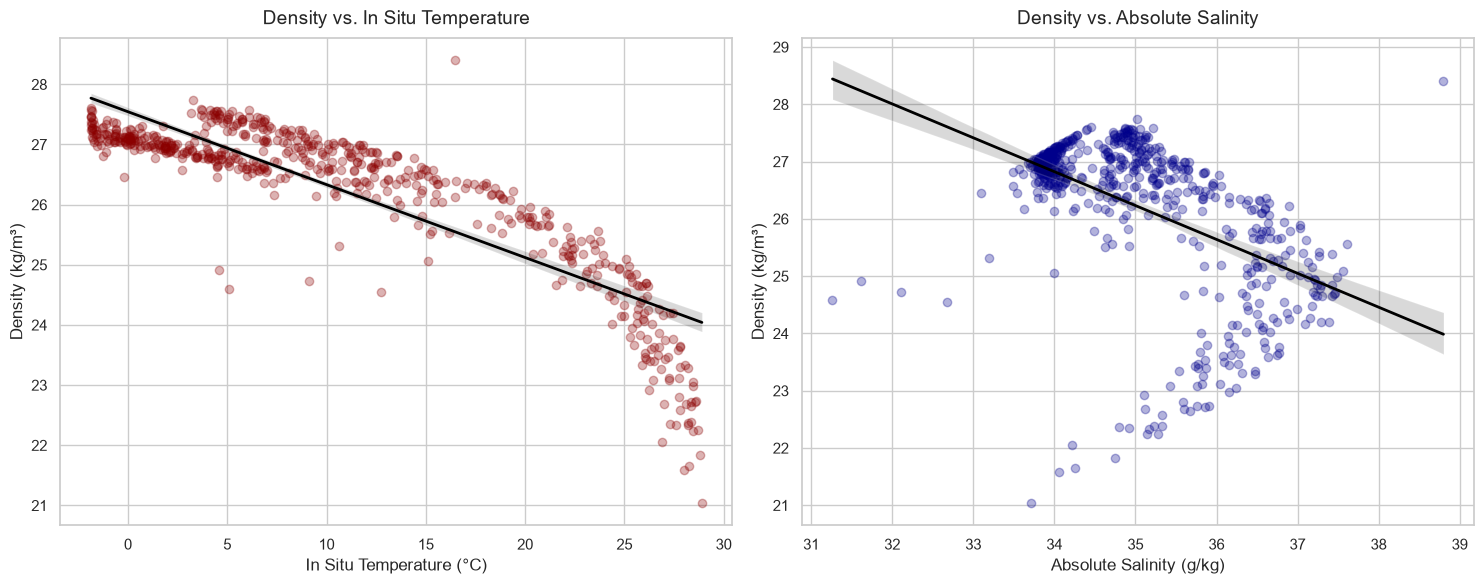

In [7]:
# Set up a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.set_theme(style="whitegrid")

# Plot 1: Density vs Temperature
sns.regplot(
    ax=axes[0],
    data=df,
    x='temperature_degC',
    y='density_$\rho$',
    scatter_kws={'alpha': 0.3, 'color': 'darkred'},
    line_kws={'color': 'black', 'linewidth': 2}
)
axes[0].set_title('Density vs. In Situ Temperature', fontsize=14, pad=10)
axes[0].set_xlabel('In Situ Temperature (°C)', fontsize=12)
axes[0].set_ylabel('Density (kg/m³)', fontsize=12)

# Plot 2: Density vs Salinity
sns.regplot(
    ax=axes[1],
    data=df,
    x='salinity_g/kg',
    y='density_$\rho$',
    scatter_kws={'alpha': 0.3, 'color': 'darkblue'},
    line_kws={'color': 'black', 'linewidth': 2}
)
axes[1].set_title('Density vs. Absolute Salinity', fontsize=14, pad=10)
axes[1].set_xlabel('Absolute Salinity (g/kg)', fontsize=12)
axes[1].set_ylabel('Density (kg/m³)', fontsize=12)

plt.tight_layout()
plt.show()

**Visual Evidence of Thermal Dominance**

The regression plots provide clear visual confirmation of the statistical outputs:
*   **Thermal Control (Left Panel):** There is a tight, steeply negative linear relationship between temperature and density. The narrow scatter around the regression line visually proves that as temperature drops, density predictably and significantly increases across the entire global dataset.
*   **Haline Scatter (Right Panel):** The relationship between salinity and density is highly scattered with a much flatter trendline. While a broad positive relationship exists (saltier water is denser), the wide dispersion indicates that knowing a water mass's salinity alone is a poor predictor of its overall density compared to its temperature.

------
# ⁕ 5. Conclusion

This notebook executes a rigorous thermodynamic analysis of high-latitude surface ocean data, utilizing the Argo array to quantify the drivers of oceanic buoyancy and polar circulation. By bridging descriptive statistical methods with dynamic physical oceanography principles, this analysis yields several key findings:

*   **Distinct High-Latitude Signatures:** 
    The visualizations strongly corroborate theoretical models of polar oceanography. The North Atlantic acts as a saline heat pump, the Southern Ocean serves as an intensely cold mixing zone (driving absolute maximum densities), and the Arctic is defined by a buoyant, low-salinity freshwater cap driven by river runoff and ice melt. 

*   **Thermodynamic Sensitivity and Thermal Dominance:** 
    Through advanced empirical sensitivity modeling, this study mathematically isolates the individual thermodynamic drivers of ocean density. The regression analysis confirms that *in situ* temperature is governed by massive latitudinal insolation gradients, and acts as the primary control on general surface buoyancy. However, as demonstrated by the stratified Arctic data, salinity acts as a critical regional modifier, particularly in polar regimes where freshwater fluxes can override thermal density changes.

*   **Isopycnal Crossings and Thermohaline Preconditioning:** 
    By overlaying high-resolution basin data against background isopycnal contours, this analysis maps the exact thermodynamic preconditioning necessary to drive the "planetary cardiovascular system." The data illustrates how warm, saline Atlantic surface currents transport immense thermal energy poleward. Upon encountering frigid polar air masses, this water undergoes rapid heat loss while retaining its evaporation-driven high salinity. This specific combination forces the water mass across the highest density thresholds, initiating the deep convective sinking that powers the global thermohaline circulation.

Ultimately, this multi-faceted analysis demonstrates that the polar oceans are highly structured, dynamically linked thermodynamic engines. The ability to programmatically parse and visualize high-latitude Argo data provides critical, real-world evidence of the delicate temperature and salinity balances that sustain global climate regulation.

### Broader Impacts of High-Latitude Thermohaline Dynamics

Beyond physical circulation, the temperature and salinity gradients observed in these polar and sub-polar datasets have profound implications for global ecology and food web (OCES2004):


* **Food Web:** Increased Arctic freshwater input can reorganize marine food webs by changing turbidity, nutrient delivery, and the supply of terrestrial organic matter, which can either suppress production or provide new carbon subsidies after microbial reworking


* **Ecology:** Freshening, runoff, and sea-ice decline strengthen Arctic stratification and alter vertical mixing, heat exchange, and habitat structure, with consequences that extend from local ecosystems to the North Atlantic through downstream buoyancy and circulation changes

<center><img src="https://media1.tenor.com/m/0R-_FAO03sEAAAAd/chiikawa-usagi.gif" width="200"></center>

In conclusion, the thermohaline contrasts identified in this analysis have broader significance because they affect both marine food webs and polar ecology. In the Arctic, freshening from runoff, precipitation, and sea-ice melt strengthens stratification and alters vertical mixing, nutrient supply, and habitat structure, which can reshape biological production and food-web organization. These buoyancy changes can also spread into the North Atlantic, where fresher surface waters reduce density and suppress deep convection, linking polar ecological change to broader circulation impacts. In the Southern Ocean, sea-ice production and brine rejection help form dense shelf waters that feed Antarctic Bottom Water, so high-latitude surface change also influences the lower limb of the global overturning circulation and the storage of heat and carbon in the deep ocean. More broadly, continued warming is likely to sharpen the contrast between fresher polar waters and saltier waters elsewhere, reinforcing stratification and making overturning more sensitive to future buoyancy change.

# Bibliography
* Johnson, G., Hosoda, S., Jayne, S., Oke, P., Riser, S., Roemmich, D., Suga, T., Thierry, V., Wijffels, S., & Xu, J.-P. (2021). Argo-Two Decades: Global Oceanography, Revolutionized.. Annual review of marine science. https://doi.org/10.1146/annurev-marine-022521-102008
* Wong, A., Wijffels, S., Riser, S., Pouliquen, S., Hosoda, S., Roemmich, D., Gilson, J., Johnson, G., Martini, K., Murphy, D., Scanderbeg, M., Bhaskar, T. U. V. S., Buck, J., Merceur, F., Carval, T., Maze, G., Cabanes, C., André, X., Poffa, N., . . . Park, H. (2020). Argo Data 1999–2019: Two Million Temperature-Salinity Profiles and Subsurface Velocity Observations From a Global Array of Profiling Floats. https://doi.org/10.3389/fmars.2020.00700
* IOC, SCOR, and IAPSO, 2010: The international thermodynamic equation of seawater -2010: Calculation and use of thermodynamic properties Intergovernmental Oceanographic Commission. (n.d.). Retrieved October 15, 2026. https://www.teos-10.org/pubs/TEOS-10_Manual.pdf
* Feistel, R. (2018). Thermodynamic properties of seawater, ice and humid air: TEOS-10, before and beyond. Ocean Science. https://doi.org/10.5194/os-14-471-2018
* McDougall, T., Millero, F., Wright, D., Marion, G., Chen, A., Spitzer, P., & Seitz, S. (2010). The International Thermodynamic Equation Of Seawater 2010 (TEOS-10): Calculation and Use of Thermodynamic Properties.
* Broeker, W. (2008). The great ocean conveyor. 129-161. https://doi.org/10.1063/1.41925
* Roquet, F., Bell, M. J., De Boer, A. D., Ferreira, D., Jones, C. S., LaCasce, J., De Lavergne, C., Marshall, D. P., Munday, D., Nycander, J., & Ödalen, M. (2025). Controls of the global overturning circulation of the ocean. npj Climate and Atmospheric Science, 8. https://doi.org/10.1038/s41612-025-01185-8
* Drijfhout, S., Angevaare, J., Mecking, J., Van Westen, R. V., & Rahmstorf, S. (2025). Shutdown of northern Atlantic overturning after 2100 following deep mixing collapse in CMIP6 projections. Environmental Research Letters, 20. https://doi.org/10.1088/1748-9326/adfa3b
* OCES2004, 2026 autumn: Sustainable Ocean